In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
np.random.seed(42)
tf.random.set_seed(42)

I0000 00:00:1793080654.955044     700 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793080657.167588     700 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv(url, header=None, names=cols)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Outcome
0    500
1    268
Name: count, dtype: int64


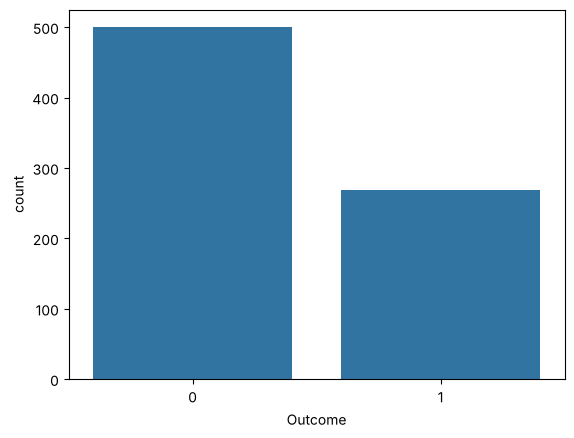

In [4]:
print(df["Outcome"].value_counts())
sns.countplot(x="Outcome", data=df)
plt.show()

In [5]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[zero_cols] == 0).sum())
df[zero_cols] = df[zero_cols].replace(0, np.nan)
df[zero_cols] = df[zero_cols].fillna(df[zero_cols].median())
print(df.isnull().sum().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
0


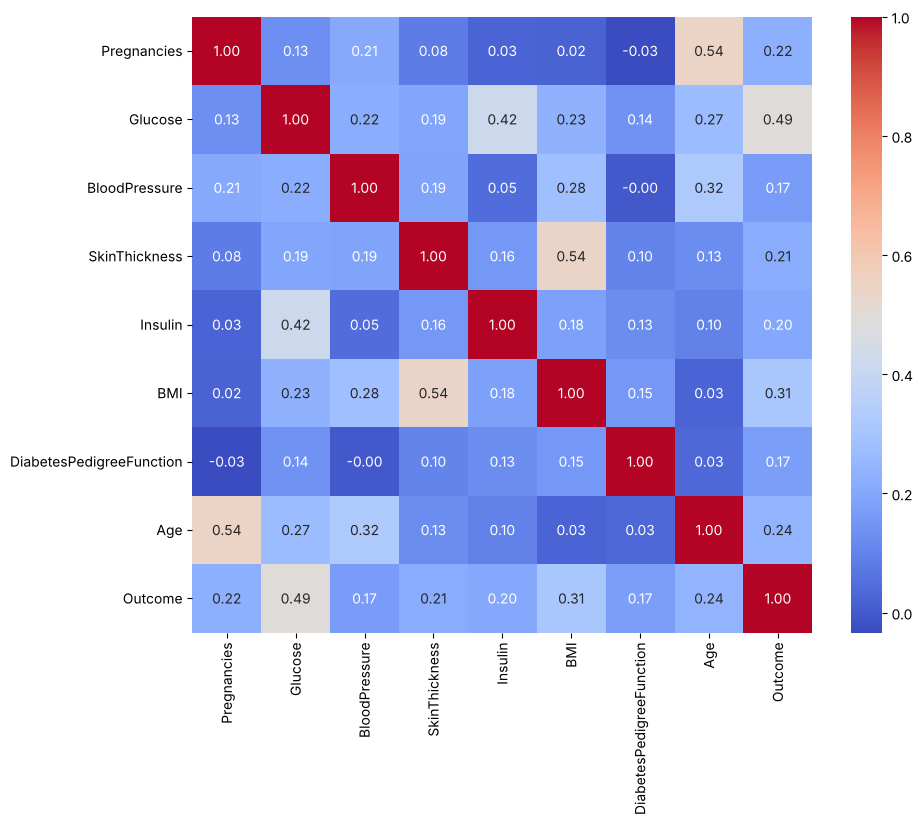

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [7]:
X = df.drop("Outcome", axis=1).values
y = df["Outcome"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


In [8]:
def create_model(neurons=12, activation="relu", init_mode="glorot_uniform", dropout_rate=0.0, learning_rate=0.001, n_features=8):
    model = models.Sequential([
        layers.Input((n_features,)),
        layers.Dense(neurons, activation=activation, kernel_initializer=init_mode),
        layers.Dropout(dropout_rate),
        layers.Dense(8, activation=activation, kernel_initializer=init_mode),
        layers.Dense(1, activation="sigmoid", kernel_initializer=init_mode),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy", metrics=["accuracy"])
    return model

class KerasClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, neurons=12, activation="relu", init_mode="glorot_uniform", dropout_rate=0.0, learning_rate=0.001, batch_size=32, epochs=50):
        self.neurons = neurons
        self.activation = activation
        self.init_mode = init_mode
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs

    def fit(self, X, y):
        tf.keras.backend.clear_session()
        self.classes_ = np.unique(y)
        self.model_ = create_model(self.neurons, self.activation, self.init_mode, self.dropout_rate, self.learning_rate, X.shape[1])
        self.model_.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=0)
        return self

    def predict_proba(self, X):
        p = self.model_.predict(X, verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
best = {}
summary = []

def run_grid(name, grid):
    gs = GridSearchCV(KerasClassifier(**best), {k: v for k, v in grid.items()}, cv=cv, scoring="accuracy", n_jobs=1)
    gs.fit(X_train, y_train)
    res = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)
    print(f"{name} -> Best: {gs.best_score_:.4f} using {gs.best_params_}")
    for _, r in res.iterrows():
        print(f"  {r.mean_test_score:.4f} ({r.std_test_score:.4f}) with {r.params}")
    best.update(gs.best_params_)
    summary.append({"Step": name, "Best Params": gs.best_params_, "CV Accuracy": round(gs.best_score_, 4)})
    return res

In [10]:
res_bs = run_grid("Batch Size & Epochs", {"batch_size": [10, 20, 40, 60], "epochs": [10, 50, 100]})

Batch Size & Epochs -> Best: 0.7866 using {'batch_size': 10, 'epochs': 10}
  0.7866 (0.0044) with {'batch_size': 10, 'epochs': 10}
  0.7736 (0.0159) with {'batch_size': 10, 'epochs': 50}
  0.7687 (0.0242) with {'batch_size': 40, 'epochs': 50}
  0.7687 (0.0164) with {'batch_size': 20, 'epochs': 50}
  0.7671 (0.0105) with {'batch_size': 20, 'epochs': 100}
  0.7655 (0.0172) with {'batch_size': 10, 'epochs': 100}
  0.7622 (0.0112) with {'batch_size': 60, 'epochs': 100}
  0.7622 (0.0056) with {'batch_size': 40, 'epochs': 100}
  0.7573 (0.0065) with {'batch_size': 60, 'epochs': 50}
  0.7280 (0.0246) with {'batch_size': 60, 'epochs': 10}
  0.7166 (0.0247) with {'batch_size': 40, 'epochs': 10}
  0.7085 (0.0441) with {'batch_size': 20, 'epochs': 10}


In [11]:
res_lr = run_grid("Learning Rate", {"learning_rate": [0.0001, 0.001, 0.01, 0.1, 0.2]})

Learning Rate -> Best: 0.7769 using {'learning_rate': 0.01}
  0.7769 (0.0140) with {'learning_rate': 0.01}
  0.7639 (0.0335) with {'learning_rate': 0.001}
  0.7573 (0.0180) with {'learning_rate': 0.1}
  0.6742 (0.0303) with {'learning_rate': 0.2}
  0.6171 (0.1007) with {'learning_rate': 0.0001}


In [12]:
res_init = run_grid("Weight Initialization", {"init_mode": ["random_uniform", "lecun_uniform", "random_normal", "zeros", "glorot_normal", "glorot_uniform", "he_normal", "he_uniform"]})

Weight Initialization -> Best: 0.7753 using {'init_mode': 'lecun_uniform'}
  0.7753 (0.0075) with {'init_mode': 'lecun_uniform'}
  0.7753 (0.0067) with {'init_mode': 'random_uniform'}
  0.7720 (0.0170) with {'init_mode': 'he_uniform'}
  0.7704 (0.0171) with {'init_mode': 'random_normal'}
  0.7638 (0.0100) with {'init_mode': 'glorot_normal'}
  0.7606 (0.0218) with {'init_mode': 'he_normal'}
  0.7590 (0.0156) with {'init_mode': 'glorot_uniform'}
  0.6515 (0.0020) with {'init_mode': 'zeros'}


In [13]:
res_act = run_grid("Activation Function", {"activation": ["softmax", "softplus", "softsign", "relu", "tanh", "sigmoid", "hard_sigmoid", "linear"]})

Activation Function -> Best: 0.7899 using {'activation': 'softplus'}
  0.7899 (0.0247) with {'activation': 'softplus'}
  0.7899 (0.0286) with {'activation': 'sigmoid'}
  0.7818 (0.0121) with {'activation': 'linear'}
  0.7785 (0.0219) with {'activation': 'softsign'}
  0.7785 (0.0154) with {'activation': 'hard_sigmoid'}
  0.7769 (0.0197) with {'activation': 'softmax'}
  0.7753 (0.0209) with {'activation': 'tanh'}
  0.7704 (0.0115) with {'activation': 'relu'}


In [14]:
res_drop = run_grid("Dropout Rate", {"dropout_rate": [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]})

Dropout Rate -> Best: 0.7964 using {'dropout_rate': 0.2}
  0.7964 (0.0140) with {'dropout_rate': 0.2}
  0.7948 (0.0210) with {'dropout_rate': 0.1}
  0.7932 (0.0195) with {'dropout_rate': 0.3}
  0.7899 (0.0143) with {'dropout_rate': 0.0}
  0.7867 (0.0113) with {'dropout_rate': 0.5}
  0.7801 (0.0107) with {'dropout_rate': 0.4}
  0.7671 (0.0065) with {'dropout_rate': 0.6}


In [15]:
res_neu = run_grid("Hidden Neurons", {"neurons": [1, 5, 10, 15, 20, 25, 30, 50]})

Hidden Neurons -> Best: 0.7964 using {'neurons': 50}
  0.7964 (0.0187) with {'neurons': 50}
  0.7915 (0.0220) with {'neurons': 20}
  0.7899 (0.0184) with {'neurons': 15}
  0.7850 (0.0136) with {'neurons': 5}
  0.7834 (0.0100) with {'neurons': 10}
  0.7801 (0.0159) with {'neurons': 30}
  0.7801 (0.0223) with {'neurons': 25}
  0.7622 (0.0095) with {'neurons': 1}


                 Step                      Best Params  CV Accuracy
  Batch Size & Epochs {'batch_size': 10, 'epochs': 10}       0.7866
        Learning Rate          {'learning_rate': 0.01}       0.7769
Weight Initialization   {'init_mode': 'lecun_uniform'}       0.7753
  Activation Function       {'activation': 'softplus'}       0.7899
         Dropout Rate            {'dropout_rate': 0.2}       0.7964
       Hidden Neurons                  {'neurons': 50}       0.7964
Final best hyperparameters: {'batch_size': 10, 'epochs': 10, 'learning_rate': 0.01, 'init_mode': 'lecun_uniform', 'activation': 'softplus', 'dropout_rate': 0.2, 'neurons': 50}


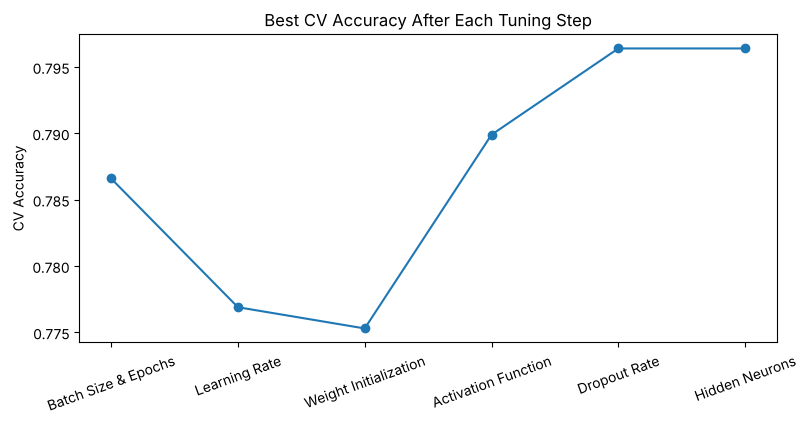

In [16]:
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))
print("Final best hyperparameters:", best)
plt.figure(figsize=(9, 4))
plt.plot(summary_df["Step"], summary_df["CV Accuracy"], marker="o")
plt.xticks(rotation=20)
plt.ylabel("CV Accuracy")
plt.title("Best CV Accuracy After Each Tuning Step")
plt.show()

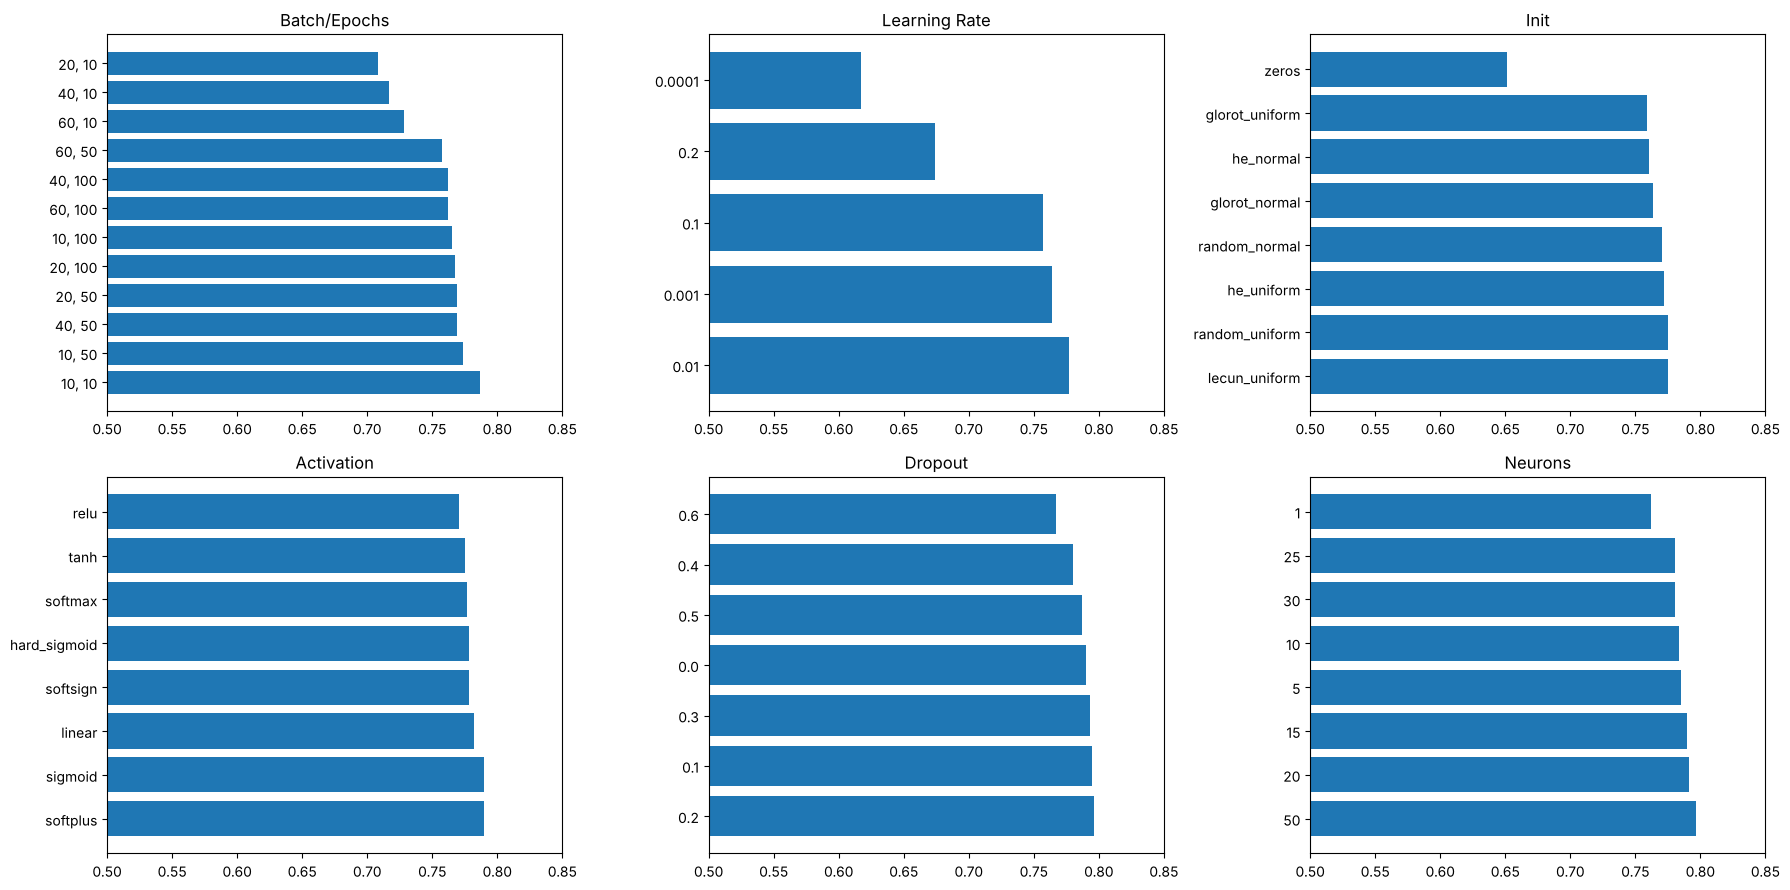

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (title, res) in zip(axes.ravel(), [("Batch/Epochs", res_bs), ("Learning Rate", res_lr), ("Init", res_init), ("Activation", res_act), ("Dropout", res_drop), ("Neurons", res_neu)]):
    labels = [", ".join(str(v) for v in p.values()) for p in res["params"]]
    ax.barh(labels, res["mean_test_score"])
    ax.set_title(title)
    ax.set_xlim(0.5, 0.85)
plt.tight_layout()
plt.show()

In [18]:
final = KerasClassifier(**best).fit(X_train, y_train)
y_prob = final.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("AUROC    :", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

Accuracy : 0.7142857142857143
Precision: 0.5961538461538461
Recall   : 0.5740740740740741
F1-score : 0.5849056603773585
AUROC    : 0.8037037037037037
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       100
           1       0.60      0.57      0.58        54

    accuracy                           0.71       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.71      0.71       154



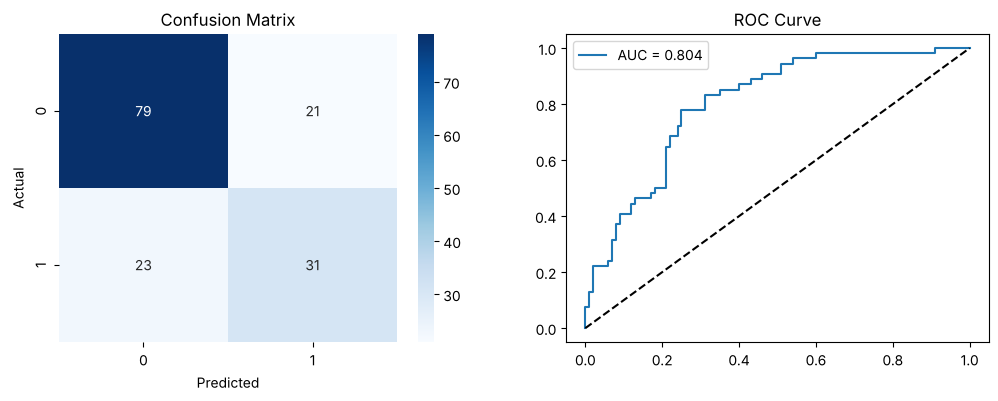

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion Matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("ROC Curve"); ax[1].legend()
plt.show()